# RouteRanker – Module 3: Exploratory Data Analysis (EDA)
**Goal:** understand the feature-engineered dataset from Module 2 before any preprocessing or modelling – distributions, time-of-day patterns, route comparisons, geography, correlations and data quality.

> **Read this first.** GTFS contains *planned* service. Every number here is a count of **scheduled** trips, stops or timings. There are **no passenger counts or occupancy** in the data, so this notebook never calls a route overcrowded or underutilised. Routes that look different are *candidates for further investigation*, not conclusions.

Change `CITY` to analyse another city (`bengaluru`, `chennai`, `delhi`, `hyderabad`, `kolkata`); the sentences printed under "Observations" are computed from the data, so they update automatically. `python run_module3.py` repeats the whole analysis for all cities and writes the report and the figures.

**What this dataset can and cannot show.** The files collected in Module 1 are route-level summaries. They give distinct trips, distinct stops, first/last trip start, operating days, route length and some timings, but *not* trips per hour, stop coordinates or route paths. Sections that need those (hourly trips, maps, route overlap) switch on automatically when the raw GTFS is placed in `data/raw/gtfs/`; until then the notebook says so instead of drawing an unsupported chart.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
sys.path.insert(0, os.getcwd())
import eda
import routeranker_features as rf
from run_module2 import discover_city_files, load_table, find_gtfs_source
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 60)

DATA = "data/processed/route_features_engineered.csv"      # created by Module 2 (python run_module2.py)
assert os.path.exists(DATA), "Run Module 2 first: python run_module2.py"
CITY = "bengaluru"    # bengaluru, chennai, delhi, hyderabad, kolkata
df_all = eda.load_dataset(DATA)
R = eda.analyze(CITY, df_all)
rf_, sh, p, h = R["rf"], R["sh"], R["p"], R["h"]
print(f"{CITY}: {len(rf_):,} routes with scheduled trips ({R['n_without_trips']} more routes have no trips in the feed and are left out)")

bengaluru: 7,475 routes with scheduled trips (18 more routes have no trips in the feed and are left out)


## 1–2. Loading and inspecting the dataset
The dataset has one row per route (per direction where the feed splits directions). Only routes that have at least one scheduled trip are analysed; routes with `n_trips = 0` cannot be compared on service.

In [2]:
print("shape (rows, columns):", rf_.shape)
rf_[["route_id", "route_name", "route_mode", "n_trips", "n_stops", "length_km", "length_method", "service_span_h",
     "median_trip_duration_min", "first_start_period", "last_start_period"]].head(3)

shape (rows, columns): (7475, 130)


,route_id,route_name,route_mode,n_trips,n_stops,length_km,length_method,service_span_h,median_trip_duration_min,first_start_period,last_start_period
0,2-0,Kempegowda Bus Station To JP Nagara Metro Station,Bus,20,22.0,13.2,shape path,13.33,60.0,Morning,Evening
1,2-1,JP Nagara Metro Station To Kempegowda Bus Station,Bus,22,20.0,11.7,shape path,13.83,60.0,Morning,Evening
2,2-A-0,Kempegowda Bus Station To JP Nagara 1st Phase,Bus,2,20.0,12.6,shape path,4.83,60.0,Morning,Afternoon


In [3]:
rf_[["route_id", "route_name", "n_trips", "n_stops", "length_km", "service_span_h", "first_start_period", "last_start_period"]].tail(3)

,route_id,route_name,n_trips,n_stops,length_km,service_span_h,first_start_period,last_start_period
7472,YTTMC-MBS-0,Yeshawanthapura Bus Station To Malleshwara Bus Stand,1,4.0,2.0,NaN,Afternoon,Afternoon
7473,YTTMC-YPRS-0,Yeshawanthapura Bus Station To Yeshawanthapura New Railw...,4,3.0,0.9,8.08,Morning,Afternoon
7474,YTTMC-YPRS-1,Yeshawanthapura New Railway Station To Yeshawanthapura B...,1,3.0,1.4,NaN,Evening,Evening


In [4]:
info, meta = R["info"]
print(meta)
info

7,475 routes (rows) x 14 analysed columns


,column,non-null,missing,dtype
0,route_id,7475,0,str
1,route_name,7475,0,str
2,route_mode,7475,0,str
3,n_trips,7475,0,int64
4,n_stops,7475,0,float64
5,length_km,7427,48,float64
6,length_method,7427,48,str
7,service_span_h,4363,3112,float64
8,median_trip_duration_min,7475,0,float64
9,avg_speed_kmh,7426,49,float64


`dtype` and `non-null` above show that identifiers (`route_id`, `route_name`) are text and the measurements are numbers. Missing values are *undefined*, never replaced by zero.

In [5]:
eda.describe(rf_)

,count,mean,std,min,25%,50%,75%,max
n_trips,7475.0,7.74,17.68,1.00,1.0,2.00,5.00,204.00
n_stops,7475.0,28.91,17.35,1.00,16.0,28.00,41.00,96.00
length_km,7427.0,24.38,34.17,0.10,11.8,19.60,30.45,688.80
service_span_h,4363.0,9.74,5.06,0.02,6.5,10.42,13.75,23.77
median_trip_duration_min,7475.0,67.36,35.41,0.00,44.0,69.00,90.00,660.00
avg_speed_kmh,7426.0,53.00,376.23,0.40,15.4,18.10,21.30,8265.60


In [6]:
miss = R["info"][0].query("missing > 0").set_index("column")[["missing"]]
miss["pct"] = (100 * miss["missing"] / len(rf_)).round(1)
print("missing values per analysed column (only columns with missing values):")
display(miss)
print("duplicate rows:", rf_.duplicated().sum(), "| duplicate route_id:", rf_.route_id.duplicated().sum())

missing values per analysed column (only columns with missing values):


,missing,pct
column,,
length_km,48,0.6
length_method,48,0.6
service_span_h,3112,41.6
avg_speed_kmh,49,0.7


duplicate rows: 0 | duplicate route_id: 0


**Unusual values / suitability:** `length_km` is missing where neither a shape nor stop coordinates were available; `service_span_h` is deliberately left empty where start times are not a trustworthy statement of service hours (frequency-based routes, bad times, or mostly suspect trips); `avg_speed_kmh` is only defined where both length and a positive trip duration exist. No duplicate routes exist. The dataset is suitable for exploratory analysis, with the caveats printed below.

In [7]:
for x in eda.timing_caveats(rf_): print("CAVEAT:", x)
if not eda.timing_caveats(rf_): print("No feed-level caveat detected for this city.")

No feed-level caveat detected for this city.


## 3. Univariate analysis

In [8]:
for _l in eda.obs_univariate(rf_):
    print('•', _l)

• 7,475 routes have scheduled trips. The median route has 2 scheduled trips (middle 50%: 1-5); the most-scheduled route, Kengeri Bus Station - Platform 1 To Banashankari Bus Station - Platform 5, has 204 scheduled trips.
• 57.6% of routes have fewer than 3 scheduled trips; the busiest 10% of routes hold 65.5% of all scheduled trips (a strongly skewed distribution).
• A typical route serves 28 distinct stops (middle 50%: 16-41; maximum 96).
• Route length is known for 99.4% of routes (median 19.6 km); 7,214 come from a shape path and 213 are straight-line estimates between stops (shorter than the road).
• Service span (first to last trip start) is shown only where reliable: 4,363 routes, median 10.4 hours.


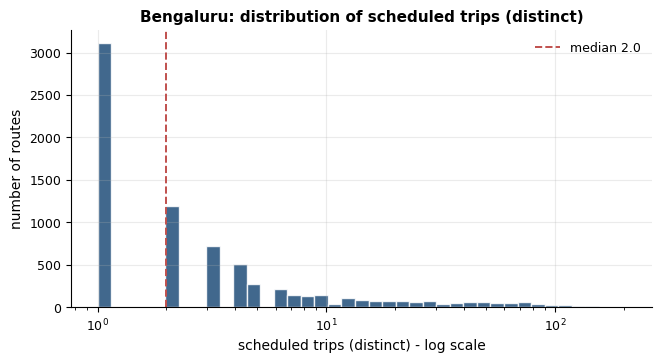

In [9]:
eda.f_hist(rf_, 'n_trips', CITY, log_x=True); plt.show()

**What it shows:** how many routes have each number of scheduled trips (log scale, because a few routes have far more trips than most). A long right tail means service levels differ strongly between routes; the dashed line is the median.

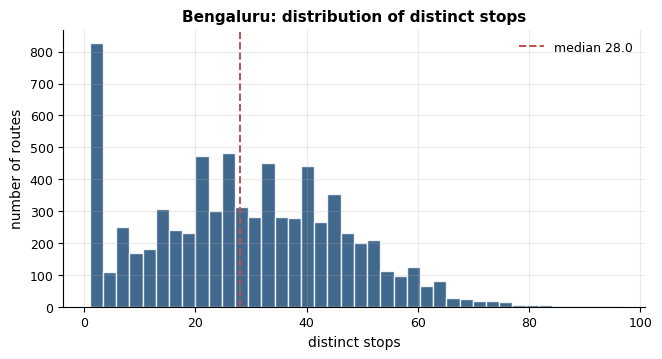

In [10]:
eda.f_hist(rf_, 'n_stops', CITY); plt.show()

**What it shows:** the spread of distinct stops per route – whether routes are broadly similar in size or differ a lot.

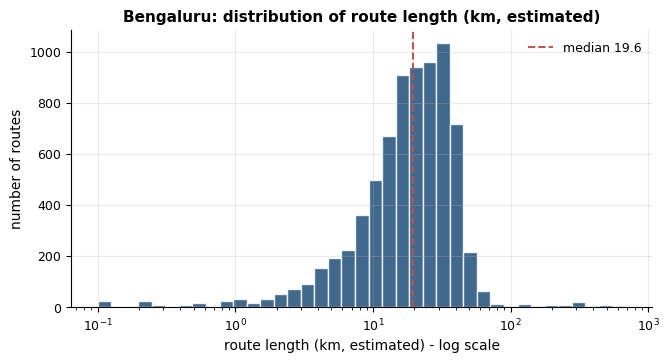

In [11]:
eda.f_hist(rf_, 'length_km', CITY, log_x=True); plt.show()

**What it shows:** estimated route length. It comes from a shape path where the feed has one, otherwise from straight-line distances between stops (an understatement of road length). The table below says which.

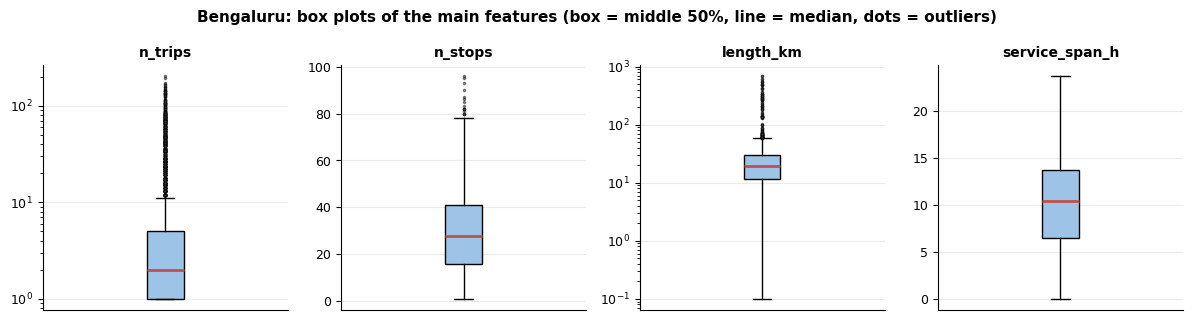

In [12]:
eda.f_box_panel(rf_, CITY); plt.show()

**What it shows:** box = middle 50% of routes, line = median, dots = statistical outliers. Outliers are examined in section 9 – not removed.

In [13]:
rf_.length_method.value_counts(dropna=False).to_frame('routes')

,routes
length_method,
shape path,7214
straight line between stops,213
NaN,48


## 4. Scheduled service by time of day
Time periods: **morning** 05:00–11:59 · **afternoon** 12:00–16:59 · **evening** 17:00–20:59 · **night** 21:00–04:59. The route-level files only give the time of each route's **first and last** scheduled trip, so this section shows *when service starts and ends*. Scheduled trips per hour need the raw GTFS and appear automatically once it is available (see the check below).

In [14]:
for _l in eda.obs_time(sh, p, rf_, h):
    print('•', _l)

• Most routes (68.5%) begin service in the morning; the most common last-trip period is the evening (35.1%).
• The most common first-trip hour is 06:00 (1,202 routes); the most common last-trip hour is 17:00 (711 routes).
• No route has a last trip scheduled after midnight.
• Scheduled trips per hour cannot be computed from the route-level files; they need the raw GTFS (stop_times.txt).


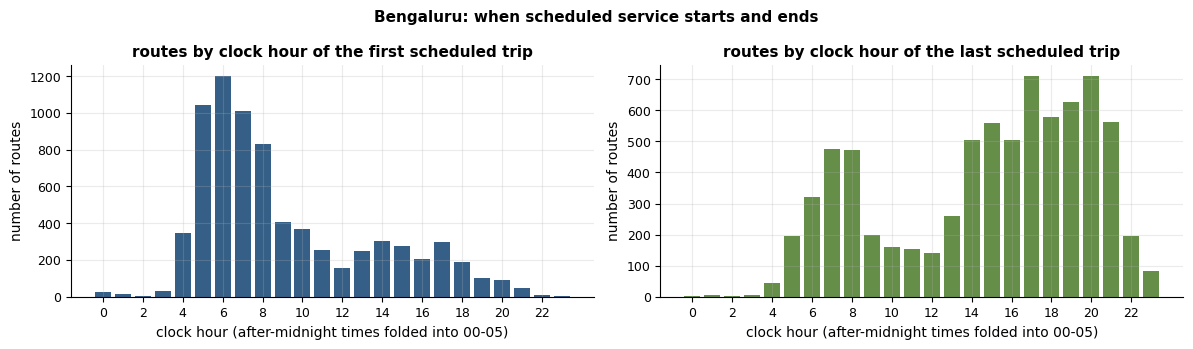

In [15]:
eda.f_start_hours(sh, CITY); plt.show()

**What it shows:** how many routes begin (left) and end (right) their scheduled day in each clock hour. After-midnight trips (GTFS hour 24 or more) are folded into hours 00–05. It describes timetables, not passenger demand.

,period,hours_in_period,routes_first_start,share_first_pct,routes_last_start,share_last_pct,first_starts_per_hour
0,Morning,7,5117,68.5,1980,26.5,731.0
1,Afternoon,5,1189,15.9,1970,26.4,237.8
2,Evening,4,682,9.1,2627,35.1,170.5
3,Night,8,487,6.5,898,12.0,60.9


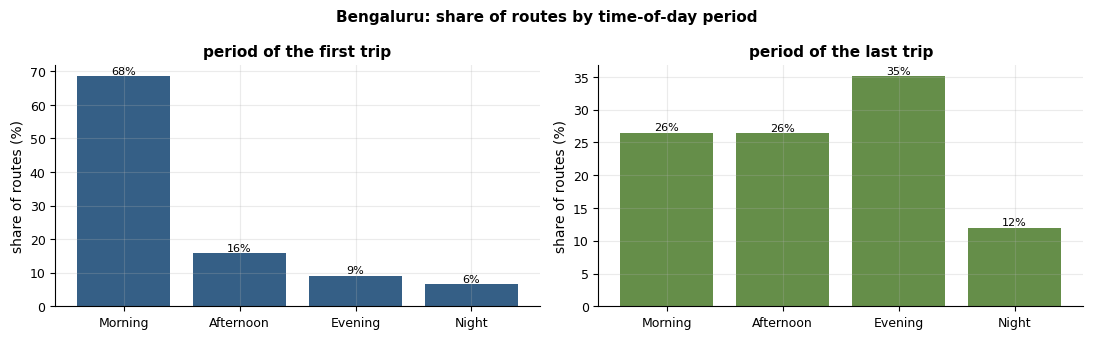

In [16]:
display(p); eda.f_period(p, CITY); plt.show()

**What it shows:** each period's share of routes by first and last trip. Periods differ in length, so `first_starts_per_hour` is the fairer comparison between periods.

In [17]:
if h is not None:
    eda.f_hourly(h, CITY); plt.show()
    display(h.sort_values("scheduled_trips", ascending=False).head(5))
else:
    print("Scheduled trips per hour are NOT available: the Module 2 dataset was built from route-level files only.")
    print("To enable this chart, put the city's GTFS zip in data/raw/gtfs/ and re-run: python run_module2.py")

Scheduled trips per hour are NOT available: the Module 2 dataset was built from route-level files only.
To enable this chart, put the city's GTFS zip in data/raw/gtfs/ and re-run: python run_module2.py


## 5. Route-wise comparison

In [18]:
for _l in eda.obs_routes(rf_, R['groups']):
    print('•', _l)

• Routes in the highest quarter by scheduled trips have a median of 13 trips vs 1 in the lowest quarter.
• Their median number of stops is 27 vs 33, and median length 17.5 km vs 22.2 km - differences in how the schedule is built, not proof of efficiency.
• Most-scheduled routes: Kengeri Bus Station - Platform 1 To Banashankari Bus Station - Platform 5 (204 trips); Banashankari Bus Station - Platform 5 To Kengeri Bus Station - Platform 1 (194 trips); Kengeri Bus Station - Platform 1 To Electronic City 378 (171 trips).


In [19]:
R['groups']

,trip_group,routes,median_trips,median_stops,median_length_km,median_service_span_h,median_duration_min
0,lowest quarter,1869,1.0,33.0,22.2,NaN,75.0
1,middle half,3737,2.0,27.0,19.8,7.7,70.0
2,highest quarter,1869,13.0,27.0,17.5,13.5,60.0


Routes are grouped by their number of scheduled trips (lowest quarter / middle half / highest quarter) and the median of other features is compared. Differences describe the schedule; they do not prove inefficiency.

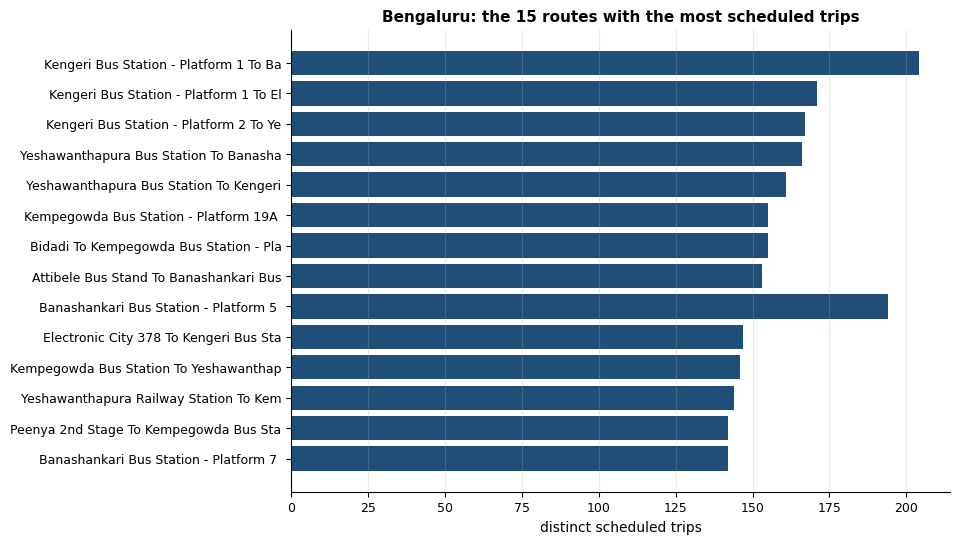

In [20]:
eda.f_top_routes(rf_, CITY); plt.show()

In [21]:
rf_.nlargest(10, 'n_trips')[['route_id', 'route_name', 'n_trips', 'n_stops', 'length_km', 'service_span_h']]

,route_id,route_name,n_trips,n_stops,length_km,service_span_h
4804,375-D-0,Kengeri Bus Station - Platform 1 To Banashankari Bus Sta...,204,23.0,11.8,18.00
4805,375-D-1,Banashankari Bus Station - Platform 5 To Kengeri Bus Sta...,194,23.0,12.6,17.83
4836,378-1,Kengeri Bus Station - Platform 1 To Electronic City 378,171,58.0,29.9,17.42
4998,401-M-0,Kengeri Bus Station - Platform 2 To Yeshawanthapura Bus ...,167,38.0,20.2,18.17
5091,410-FA-1,Yeshawanthapura Bus Station To Banashankari Bus Station ...,166,32.0,20.7,17.17
4999,401-M-1,Yeshawanthapura Bus Station To Kengeri Bus Station - Pla...,161,38.0,23.7,18.17
1175,226-N-0,Kempegowda Bus Station - Platform 19A To Bidadi,155,43.0,30.7,19.92
1176,226-N-1,Bidadi To Kempegowda Bus Station - Platform 19A,155,44.0,31.2,17.92
5470,600-F-1,Attibele Bus Stand To Banashankari Bus Station - Platform 7,153,39.0,29.2,18.40
5090,410-FA-0,Banashankari Bus Station - Platform 5 To Yeshawanthapura...,150,31.0,21.0,17.33


In [22]:
R['low'].head(10)

,route_id,route_name,n_trips,n_stops,length_km,length_method,service_span_h
4912,399-F D27G-ANK-HSK-1,Hosakote Bus Stand (Old) To Depot-27 Gate,1,96.0,65.9,shape path,NaN
4911,399-F D27G-ANK-HSK-0,Depot-27 Gate To Hosakote Bus Stand (Old),1,95.0,68.9,shape path,NaN
2055,256-MB-1,Magadi Bus Stand To KR Market,1,93.0,86.6,shape path,NaN
2054,256-MB-0,KR Market To Magadi Bus Stand,1,90.0,68.8,shape path,NaN
1780,248-HA NMG-NMG-0,Nelamangala Bus Station To Nelamangala Bus Station,1,87.0,51.6,shape path,NaN
1515,240-N-0,KR Market (Kalasipalya) - Platform 6B To Heligehalli Colony,1,82.0,65.1,shape path,NaN
4888,398-H-0,Jigani APC Circle To Hosakote Bus Stand (Old),1,81.0,61.3,shape path,NaN
1516,240-N-1,Heligehalli Colony To KR Market (Kalasipalya) - Platform 6B,1,80.0,68.4,shape path,NaN
1503,240-K-1,Biskur To KR Market (Kalasipalya) - Platform 6A,1,77.0,73.1,shape path,NaN
832,213-VD VSD-HRHD-0,Vidhana Soudha To Dayananda Sagara MDC,1,77.0,41.9,straight line between stops,NaN


**Further information needed for stronger conclusions:** ridership/boardings per route and time period (matched to GTFS route ids and dates), vehicle capacity and fleet allocation, measured run times, operating costs, and the operator's purpose for each route (feeder, express, coverage).

## 6. Geographical analysis and route density
Maps need **stop coordinates** (`stops.txt`) and path maps need **`shapes.txt`**; the route-level Module 1 files contain neither. So this section checks whether the raw GTFS for the city is available and, if it is not, **draws nothing** instead of an unsupported map.

In [23]:
RAW_DIR, GTFS_DIR = "data/raw", "data/raw/gtfs"
from pathlib import Path
city_files, _ = discover_city_files(Path(RAW_DIR))
zip_name = load_table(city_files[CITY])["GTFS zip"].mode().iat[0] if CITY in city_files else None
source = find_gtfs_source(zip_name, CITY, [Path(GTFS_DIR), Path(RAW_DIR)])

if source is None:
    print(f"No raw GTFS found for {CITY} (looked for '{zip_name}' in {GTFS_DIR}/).")
    print("-> stop map, route density and stop-based overlap are NOT drawn for this city.")
else:
    tables = rf.read_gtfs(source, tables=("trips", "stop_times", "stops"))
    su, meta = eda.stop_usage(tables)
    print(meta)
    eda.f_stop_scatter(su, CITY); plt.show()

No raw GTFS found for bengaluru (looked for 'bengaluru_bmtc_gtfs.zip' in data/raw/gtfs/).
-> stop map, route density and stop-based overlap are NOT drawn for this city.


**How the geography and overlap code works (shown on the small practice feed).** *Stop usage:* for every stop, count the distinct routes that call there; *overlap:* for each pair of routes, the Jaccard similarity = shared stops ÷ all distinct stops of the two routes. Two routes that share stops are **not necessarily redundant** – they may serve different passengers, and these data say nothing about traffic.

In [24]:
from make_sample_gtfs import build_sample_gtfs_zip
demo = rf.read_gtfs(build_sample_gtfs_zip("data/raw/gtfs/sample_city_gtfs.zip"), tables=("trips", "stop_times", "stops"))
su_demo, meta_demo = eda.stop_usage(demo)
print(meta_demo, "(stop S6 has a blank coordinate and is left out)")
display(su_demo[["stop_id", "stop_name", "n_routes", "n_trips", "lat", "lon"]])
eda.route_stop_overlap(demo, min_jaccard=0.5, min_stops=2)

{'stops_used': 6, 'invalid_coordinates': 1} (stop S6 has a blank coordinate and is left out)


,stop_id,stop_name,n_routes,n_trips,lat,lon
0,S1,Central,5,8,12.900,77.6
1,S2,Market,4,8,12.909,77.6
2,S3,Park,1,3,12.918,77.6
3,S4,Station,1,2,12.927,77.6
4,S5,Airport,1,2,12.936,77.6


,route_a,route_b,shared_stops,stops_a,stops_b,jaccard
0,R3,R4,2,2,2,1.000
1,R2,R3,2,3,2,0.667
2,R2,R4,2,3,2,0.667
3,R1,R4,2,4,2,0.500
4,R1,R3,2,4,2,0.500


`R3` and `R4` call at exactly the same two stops (Jaccard 1.0) and `R2`/`R3` share 2 of 3 stops (0.67). With real feeds the threshold is 0.8 and routes need at least 5 stops. Run on a real city this produces the list used in section 7.

## 7. Routes that are candidates for further investigation

In [25]:
print("routes with very few scheduled trips (lowest 10%):", len(R["low"]), "| with fewer than 3:", int(rf_.sparse_schedule.sum()))
rf_[rf_.n_trips < 3][["route_name", "n_trips", "n_stops", "length_km", "service_span_h"]].head(8)

routes with very few scheduled trips (lowest 10%): 3112 | with fewer than 3: 4303


,route_name,n_trips,n_stops,length_km,service_span_h
2,Kempegowda Bus Station To JP Nagara 1st Phase,2,20.0,12.6,4.83
3,JP Nagara 1st Phase To Kempegowda Bus Station,2,20.0,11.0,4.83
4,JP Nagara 6th Phase To Vidhana Soudha Karnataka High Court,1,20.0,11.5,NaN
5,Vidhana Soudha Karnataka High Court To JP Nagara 6th Phase,1,19.0,11.0,NaN
6,Kempegowda Bus Station To JP Nagara 6th Phase,2,20.0,12.7,7.33
8,Kuvempunagara 2nd stage To Jalahalli East,1,5.0,3.1,NaN
9,Jalahalli East To Kuvempunagara 2nd stage,1,5.0,3.1,NaN
10,Anekal To Head Start School Kommasandra,1,29.0,19.5,NaN


These lists are **observations to follow up**, not findings. A route with few trips may be a feeder, school or peak-only service, or the feed may simply record fewer trips for it; routes that overlap may serve different passengers. Reliable ridership and operational information is required before calling any route underutilised or suitable for merging.

## 8. Statistical analysis and correlation

In [26]:
for _l in eda.obs_corr(rf_):
    print('•', _l)

• length_km and median_trip_duration_min: Spearman rho = +0.86
• n_stops and median_trip_duration_min: Spearman rho = +0.82
• n_stops and length_km: Spearman rho = +0.81
• n_trips and service_span_h: Spearman rho = +0.64
• avg_speed_kmh is calculated from length and duration, so its correlation with them holds by definition and is not listed.


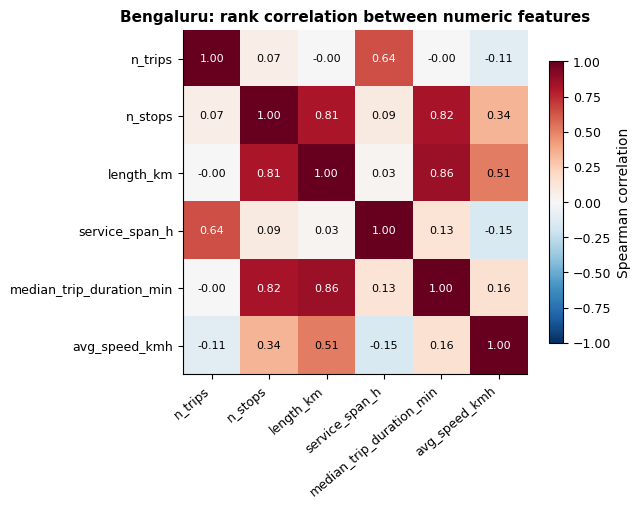

In [27]:
eda.f_corr(rf_, CITY); plt.show()

**What it shows:** Spearman correlation (rank-based, robust to the skew in trip counts) between numeric features; identifiers are excluded. +1 = rise together, −1 = one rises as the other falls, 0 = no consistent link. `avg_speed_kmh` is calculated from length and duration, so its links with them hold by definition. Correlation is association, not causation.

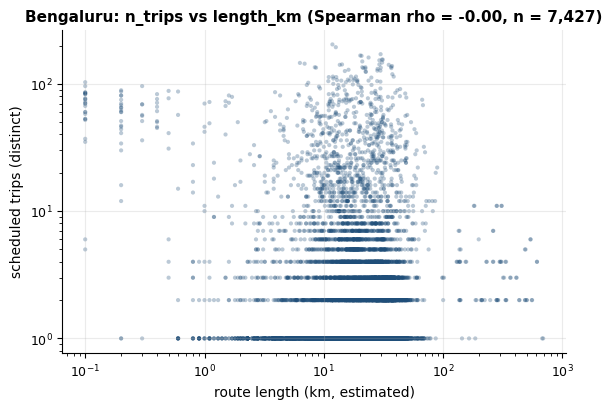

In [28]:
eda.f_scatter(rf_, 'length_km', 'n_trips', CITY); plt.show()

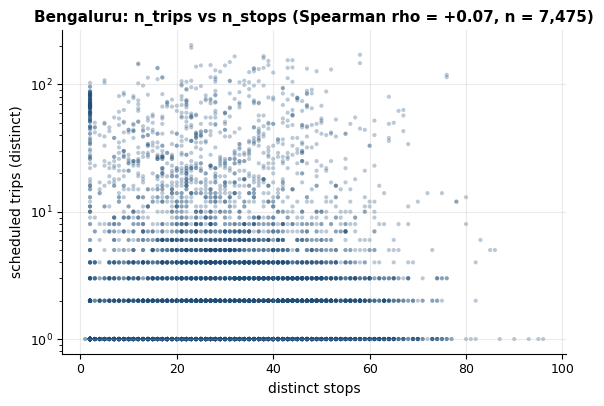

In [29]:
eda.f_scatter(rf_, 'n_stops', 'n_trips', CITY, log_x=False, log_y=True); plt.show()

## 9. Data quality and outlier analysis

In [30]:
R['out']

,feature,values,scale,lower_fence,upper_fence,outliers_high,outliers_low,pct_outliers,max_value
0,n_trips,7475,log10,0.1,55.9,255,0,3.4,204.0
1,n_stops,7475,linear,0.0,78.5,15,0,0.2,96.0
2,length_km,7427,log10,2.8,126.2,76,304,5.1,688.8
3,service_span_h,4363,linear,0.0,24.6,0,0,0.0,23.8
4,median_trip_duration_min,7472,log10,15.0,263.3,3,664,8.9,660.0


Tukey fences (1.5 × IQR; on a log scale for skewed features) mark *statistical* outliers. They are investigated below, **not deleted**.

In [31]:
R['inv']

,rule,routes,share_pct,why it matters
0,scheduled trips above the Tukey upper fence,255,3.4,unusually many trips; check whether they are real servic...
1,route length above 150 km,61,0.8,intercity service or a wrong shape / coordinates
2,implied speed below 3 or above 80 km/h,118,1.6,length and duration contradict each other
3,median trip duration above 600 min,1,0.0,implausible for one bus trip; timetable problem
4,median trip duration is 0 min,3,0.0,times at all stops are identical; placeholder schedule?
5,fewer than 3 scheduled trips,4303,57.6,"feeder, school, peak-only or incomplete schedule"
6,"placeholder route name (NONE, NA ...)",0,0.0,probably a catch-all route in the source
7,service hours withheld (not reliable),0,0.0,"frequency-based, bad times or mostly suspect trips"
8,frequency-based route,0,0.0,trip count describes template trips only


In [32]:
for _l in eda.obs_outliers(rf_, R['inv']):
    print('•', _l)

• 255 routes (3.4%): scheduled trips above the Tukey upper fence - unusually many trips; check whether they are real services or a catch-all route.
• 61 routes (0.8%): route length above 150 km - intercity service or a wrong shape / coordinates.
• 118 routes (1.6%): implied speed below 3 or above 80 km/h - length and duration contradict each other.
• 1 route (0.0%): median trip duration above 600 min - implausible for one bus trip; timetable problem.


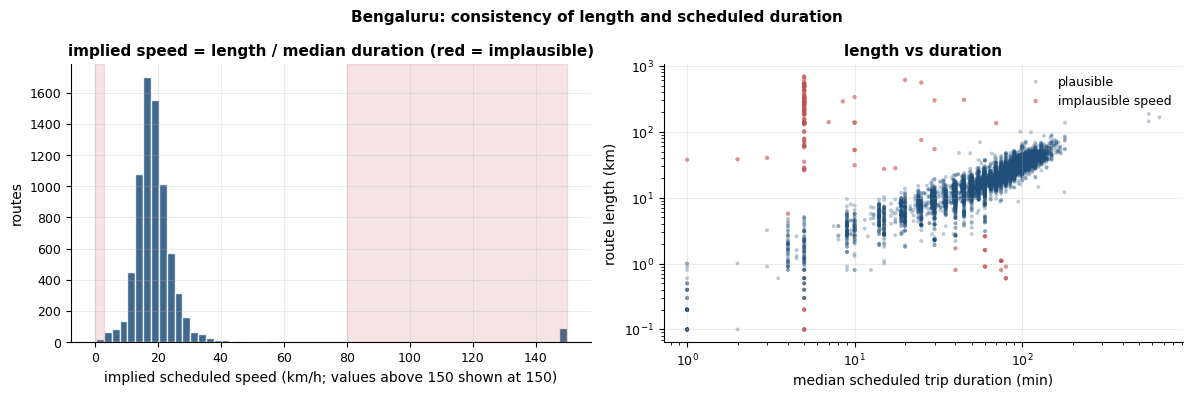

In [33]:
eda.f_outliers(rf_, CITY); plt.show()

In [34]:
print("implausible scheduled speed (<3 or >80 km/h):", int(rf_.speed_implausible.sum()), "routes")
rf_[rf_.speed_implausible][["route_name", "n_trips", "length_km", "median_trip_duration_min", "avg_speed_kmh", "length_method"]].head(8)

implausible scheduled speed (<3 or >80 km/h): 118 routes


,route_name,n_trips,length_km,median_trip_duration_min,avg_speed_kmh,length_method
3677,Kempegowda Bus Station To Depot-51 Sadaramangala Arrival,1,26.0,5.0,312.0,shape path
5903,Depot-12 Gate To Muneshwara Layout,1,5.7,4.0,85.5,shape path
5935,Depot-19 Electronic City To Electronic City,16,0.2,5.0,2.4,straight line between stops
5940,Depot-20 Banashankari To Banashankari Bus Station,81,0.2,5.0,2.4,straight line between stops
6000,Hebbala Bridge To Depot-28 Hebbala,83,0.1,5.0,1.2,straight line between stops
6200,Depot-07 Subhashnagara To Kempegowda Bus Station - Platf...,84,0.1,5.0,1.2,straight line between stops
6201,Kempegowda Bus Station - Platform 5 To Depot-07 Subhashn...,86,0.1,5.0,1.2,straight line between stops
6233,Kempegowda Bus Station To Doddaballapura Bus Stand,1,38.3,2.0,1149.0,shape path


**Reading the table:** a very long route whose scheduled speed is plausible is *valid but unusual* (e.g. an intercity service); a route whose length and duration contradict each other is *suspect*; and some patterns are *source limitations* (e.g. a catch-all route named `NONE`, or generated timetables). Flagged rows stay in the data (`dq_flags`, `speed_implausible`, `sparse_schedule`). The raw files in `data/raw/` are untouched; no corrections or exclusions were applied in this module.

## 10. Findings and limitations

In [35]:
print("What this analysis supports:")
for x in eda.obs_univariate(rf_)[:2] + eda.obs_time(sh, p, rf_, h)[:1]: print(" •", x)
print()
print("What it does NOT support: passenger demand, crowding, load factors, or any 'overcrowded' / 'underutilised' verdict; and whether overlapping routes should be merged.")

What this analysis supports:
 • 7,475 routes have scheduled trips. The median route has 2 scheduled trips (middle 50%: 1-5); the most-scheduled route, Kengeri Bus Station - Platform 1 To Banashankari Bus Station - Platform 5, has 204 scheduled trips.
 • 57.6% of routes have fewer than 3 scheduled trips; the busiest 10% of routes hold 65.5% of all scheduled trips (a strongly skewed distribution).
 • Most routes (68.5%) begin service in the morning; the most common last-trip period is the evening (35.1%).

What it does NOT support: passenger demand, crowding, load factors, or any 'overcrowded' / 'underutilised' verdict; and whether overlapping routes should be merged.


**Limitations**
* Scheduled data only – no ridership, occupancy or delays.
* The Module 1 route-level files give first/last trip times, not trips per hour; hourly patterns, stop maps and overlap need the raw GTFS.
* Route length is a shape-based estimate where a shape exists, otherwise a straight-line lower bound; Chennai and Delhi lengths are all straight-line.
* Several feeds show signs of unreliable or generated timetables (Hyderabad durations, Delhi constant-speed times – Delhi's open-data page says so), and Kolkata is frequency-based, so trip counts there are not comparable with other cities.
* Hyderabad contains two catch-all routes named `NONE`; Mumbai's file contained Bengaluru data and is excluded.
* Cities were compared using the same rules, but their feeds were built differently; differences between cities may reflect how the data were compiled rather than how service differs.

## 11. City comparison
The same rules applied to every city. Read it with the caveats above: Kolkata's trip counts are template trips, Hyderabad's durations are unreliable, and only Bengaluru has shape-based lengths.

In [36]:
cmp = eda.city_comparison(df_all)
cmp

,city,routes_with_trips,median_trips,p90_trips,median_stops,median_length_km,length_known_pct,length_from_shape_pct,median_duration_min,service_hours_reliable_pct,frequency_based_pct,fewer_than_3_trips_pct,implausible_speed_pct
0,bengaluru,7475,2.0,18.0,28.0,19.6,99.4,96.5,69.0,100.0,0.0,57.6,1.6
1,chennai,3934,4.0,30.0,23.0,15.4,100.0,0.0,43.0,100.0,0.0,39.6,0.0
2,delhi,543,17.0,82.0,39.0,21.5,99.1,0.0,129.3,99.1,0.0,15.1,0.0
3,hyderabad,2016,4.0,58.0,29.0,25.3,99.5,0.1,836.1,17.5,0.0,37.9,74.3
4,kolkata,608,2.0,2.0,14.0,13.1,11.0,0.0,114.5,0.0,100.0,99.3,0.0


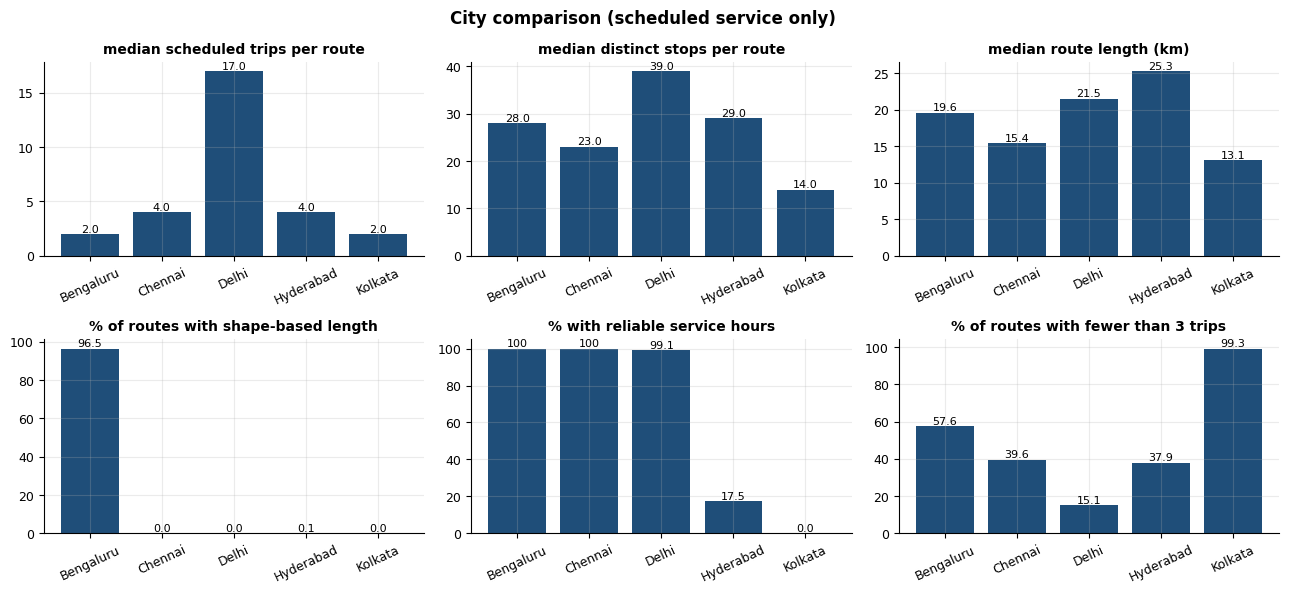

In [37]:
eda.f_city_comparison(cmp); plt.show()

**Next module:** data preprocessing – decide with the mentor how to treat flagged rows (catch-all routes, implausible durations, frequency-based routes) and non-comparable feeds, obtain the real Mumbai file and the raw GTFS for every city, and find out whether a real ridership source can be obtained.